In [20]:
# Imports necessary libraries/modules
# Reads data files
# Imports necessary functions from the run_analysis.py file
# While importing functions, this code will also print the dataframe tables returned by those functions.
# sys.path.append ensures that imported functions are recognized.
import os
import sys

sys.path.append(os.path.abspath('../src'))

from run_analysis import weapon_statistics
from run_analysis import type_of_crime_statistics
from run_analysis import mocodes_statistics
from run_analysis import poverty_and_spa_crime
from run_analysis import unemployment_analysis
from run_analysis import premise_statistics
from run_analysis import part1_part2_crimes_analysis
from run_analysis import poverty_and_district_crime
from run_analysis import csa_crime_poverty_data
from run_analysis import csa_crime_unemployment_data

import seaborn as sns
import geopandas as gpd
import textwrap
import matplotlib.pyplot as plt
import pandas as pd

gdf_joined_crime_districts = gpd.read_file("../data/processed/combined_crime_districts_data_processed.geojson")
gdf_districts = gpd.read_file("../data/processed/districts_data_processed.geojson")
results_df = pd.read_json("../data/processed/crime_data_processed.json")
gdf_spa = gpd.read_file("../data/processed/spa_data_processed.geojson")
gdf_joined_crime_spa = gpd.read_file("../data/processed/combined_crime_spa_data_processed.geojson")
gdf_unemployment = gpd.read_file("../data/processed/unemployment_data_processed.geojson")
gdf_csa_filtered = gpd.read_file("../data/processed/csa_data_processed.geojson")
gdf_joined_crime_csa = gpd.read_file("../data/processed/combined_crime_csa_data_processed.geojson")


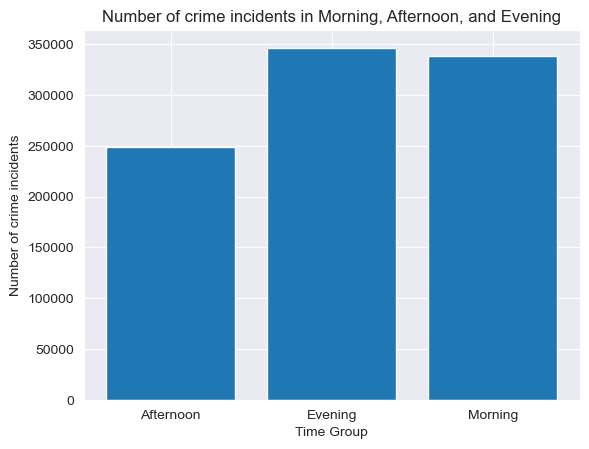

In [21]:
def crime_per_time_groups() -> None:
    """
    Creates a bar graph showing the number of crime incidents per time group (Morning, Afternoon, Evening).
    :return: None
    """
    time_groups_crime_count = pd.DataFrame(results_df.groupby("Time Groups")["dr_no"].count()).reset_index()
    time_groups_crime_count = time_groups_crime_count.rename(columns={"dr_no": "Number of crime incidents"})
    plt.bar("Time Groups", "Number of crime incidents", data=time_groups_crime_count)
    plt.title("Number of crime incidents in Morning, Afternoon, and Evening")
    plt.ylabel("Number of crime incidents")
    plt.xlabel("Time Group")
    plt.show()


crime_per_time_groups()


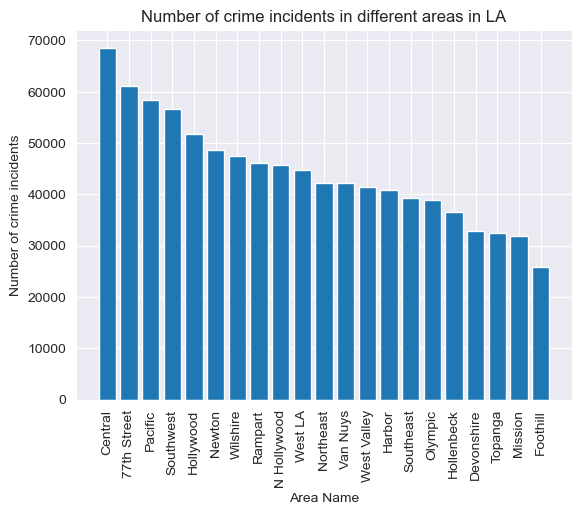

In [22]:
def crime_per_area() -> None:
    """
    Creates a bar graph showing the number of crime incidents in different areas in LA.
    The metadata describes areas as the following:
    "The LAPD has 21 Community Police Stations referred to as Geographic Areas within the department."
    :return: None
    """
    crime_count_per_area = pd.DataFrame(results_df.groupby("area_name")["dr_no"].count()).reset_index()
    crime_count_per_area = crime_count_per_area.rename(columns={"dr_no": "Number of crime incidents"})
    crime_count_per_area = crime_count_per_area.sort_values(by="Number of crime incidents", ascending=False)
    plt.bar("area_name", "Number of crime incidents", data=crime_count_per_area)
    plt.xticks(rotation=90)
    plt.title("Number of crime incidents in different areas in LA")
    plt.ylabel("Number of crime incidents")
    plt.xlabel("Area Name")
    plt.show()


crime_per_area()

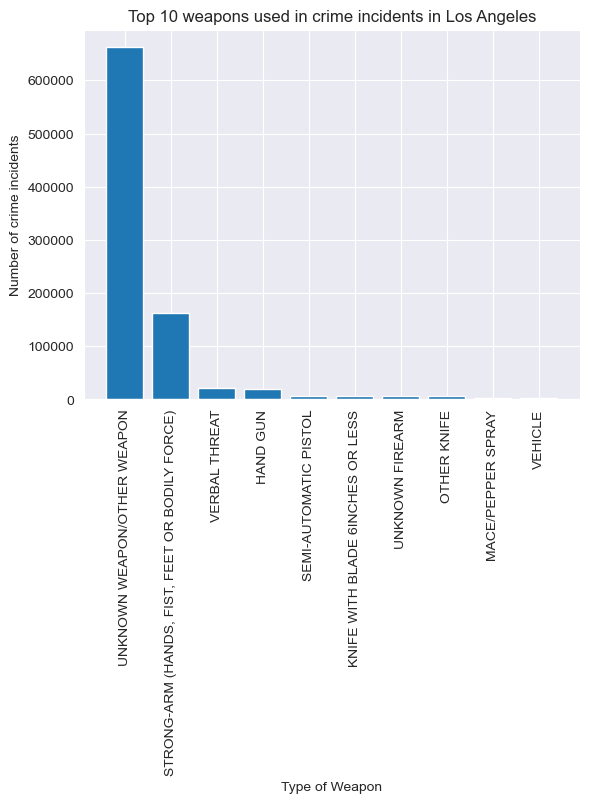

In [23]:
def weapon_statistics_graph() -> None:
    """
    Creates a bar graphing showing the top 10 weapons used in crime incidents in Los Angeles.
    :return: None
    """
    weapon_df, table = weapon_statistics()
    plt.bar("Weapon Description", "Number of crime incidents", data=weapon_df)
    plt.xticks(rotation=90)
    plt.title("Top 10 weapons used in crime incidents in Los Angeles")
    plt.ylabel("Number of crime incidents")
    plt.xlabel("Type of Weapon")
    plt.show()


weapon_statistics_graph()


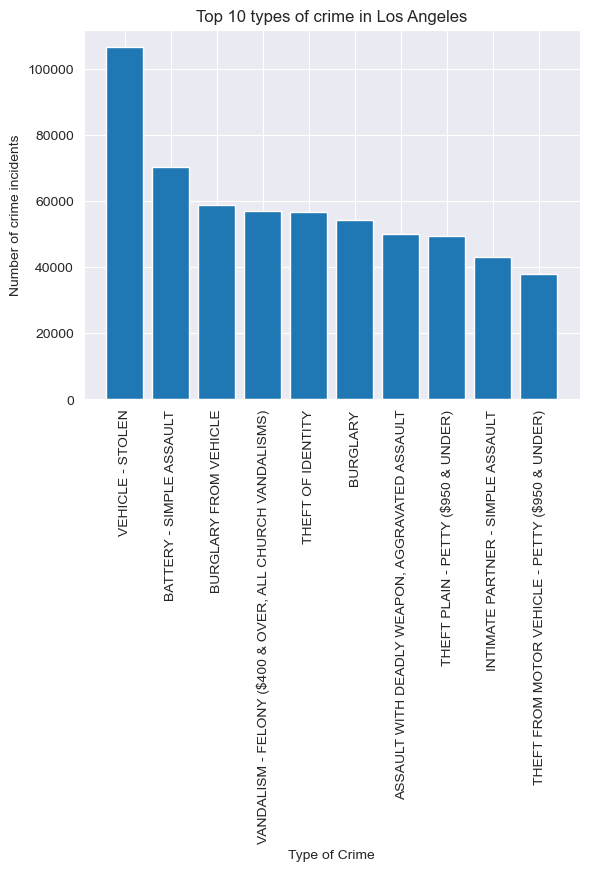

In [24]:
def types_of_crime() -> None:
    """
    Creates a bar graph showing the top 10 types of crime in Los Angeles.
    :return: None
    """
    types_of_crime_stats, table = type_of_crime_statistics()
    plt.bar("Type of Crime", "Number of crime incidents", data=types_of_crime_stats)
    plt.xticks(rotation=90)
    plt.title("Top 10 types of crime in Los Angeles")
    plt.ylabel("Number of crime incidents")
    plt.xlabel("Type of Crime")
    plt.show()


types_of_crime()


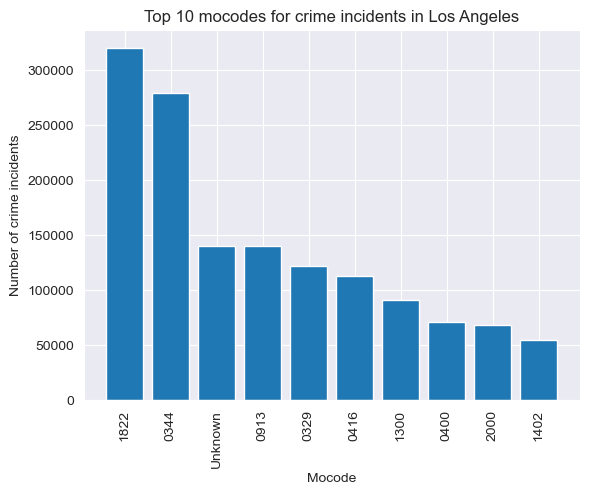

In [25]:
def mocodes_statistics_graph() -> None:
    """
    Creates a bar graphing showing the top 10 mocodes for crime incidents in Los Angeles.
    :return: None
    """
    mocodes_df, table = mocodes_statistics()
    plt.bar("Mocode", "Number of crime incidents", data=mocodes_df)
    plt.xticks(rotation=90)
    plt.title("Top 10 mocodes for crime incidents in Los Angeles")
    plt.ylabel("Number of crime incidents")
    plt.xlabel("Mocode")
    plt.show()


mocodes_statistics_graph()


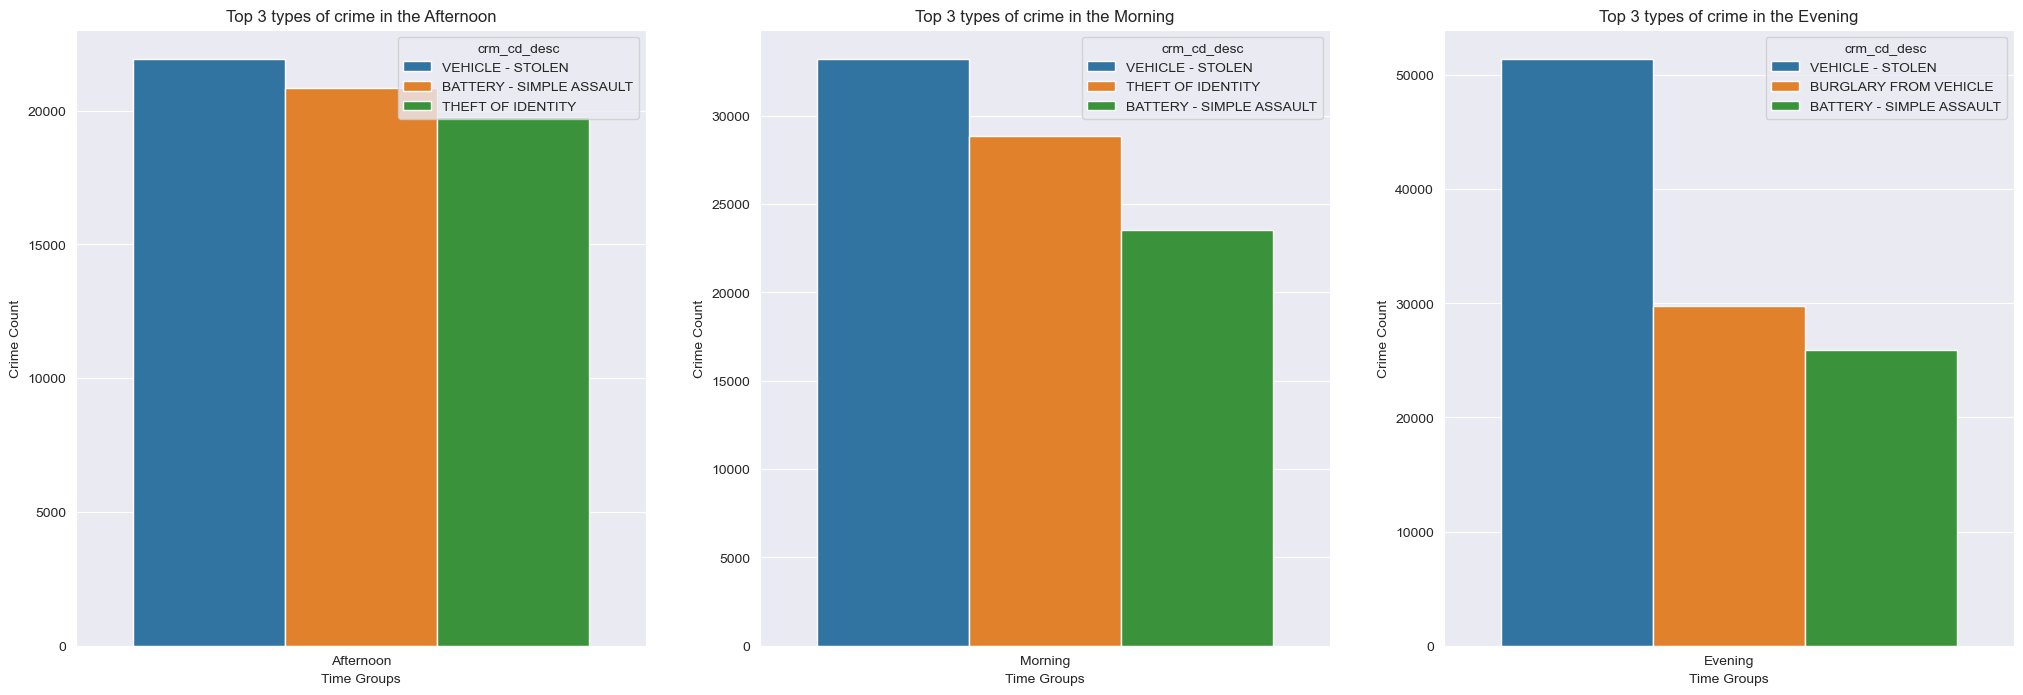

In [26]:
# The following lines of code obtains the three most frequent types of crime that occurs in each Time Group.

# Obtains the dr_no, crm_cd_desc, and Time Groups columns from the crime dataset.
# Obtains the number of crimes per type of crime per Time Group.
# Sorts the dataframe by Time Groups and number of crime incidents.
results_df_time_groups = results_df[['dr_no', 'crm_cd_desc', 'Time Groups']]
results_df_time_groups_crime_count = results_df_time_groups.groupby(['Time Groups', 'crm_cd_desc'])['dr_no'].count()
results_df_time_groups_crime_count_df = pd.DataFrame(results_df_time_groups_crime_count)
results_df_time_groups_crime_count_df = results_df_time_groups_crime_count_df.reset_index()
results_df_time_groups_crime_count_df = results_df_time_groups_crime_count_df.sort_values(
    by=["Time Groups", "dr_no"], ascending=[True, False]
)

# Obtains the top 3 types of crime in each time group
results_df_time_groups_crime_count_df = results_df_time_groups_crime_count_df.groupby("Time Groups").head(3)

# Separates the top 3 types of crime for Afternoon time group into one dataframe
top_3_crime_types_per_time_group_afternoon = results_df_time_groups_crime_count_df[
    results_df_time_groups_crime_count_df['Time Groups'] == "Afternoon"
]
top_3_crime_types_per_time_group_afternoon = top_3_crime_types_per_time_group_afternoon.rename(
    columns={'dr_no': "Crime Count"}
)

# Separates the top 3 types of crime for Morning time group into one dataframe
top_3_crime_types_per_time_group_morning = results_df_time_groups_crime_count_df[
    results_df_time_groups_crime_count_df['Time Groups'] == "Morning"
]
top_3_crime_types_per_time_group_morning = top_3_crime_types_per_time_group_morning.rename(
    columns={'dr_no': "Crime Count"}
)

# Separates the top 3 types of crime for Evening time group into one dataframe
top_3_crime_types_per_time_group_evening = results_df_time_groups_crime_count_df[
    results_df_time_groups_crime_count_df['Time Groups'] == "Evening"
]
top_3_crime_types_per_time_group_evening = top_3_crime_types_per_time_group_evening.rename(
    columns={'dr_no': "Crime Count"}
)


def types_of_crime_per_time_group() -> None:
    """
    Creates three bar graphs, one for each Time Group, each displaying the three most frequent types of crime that
    occurs in that Time Group.
    :return: None
    """
    fig, axes = plt.subplots(1, 3, figsize=(25, 8))
    sns.barplot(x="Time Groups", y="Crime Count", data=top_3_crime_types_per_time_group_afternoon, hue='crm_cd_desc',
                ax=axes[0])
    sns.barplot(x="Time Groups", y="Crime Count", data=top_3_crime_types_per_time_group_morning, hue='crm_cd_desc',
                ax=axes[1])
    sns.barplot(x="Time Groups", y="Crime Count", data=top_3_crime_types_per_time_group_evening, hue='crm_cd_desc',
                ax=axes[2])
    axes[0].set_title("Top 3 types of crime in the Afternoon")
    axes[1].set_title("Top 3 types of crime in the Morning")
    axes[2].set_title("Top 3 types of crime in the Evening")
    plt.show()


types_of_crime_per_time_group()


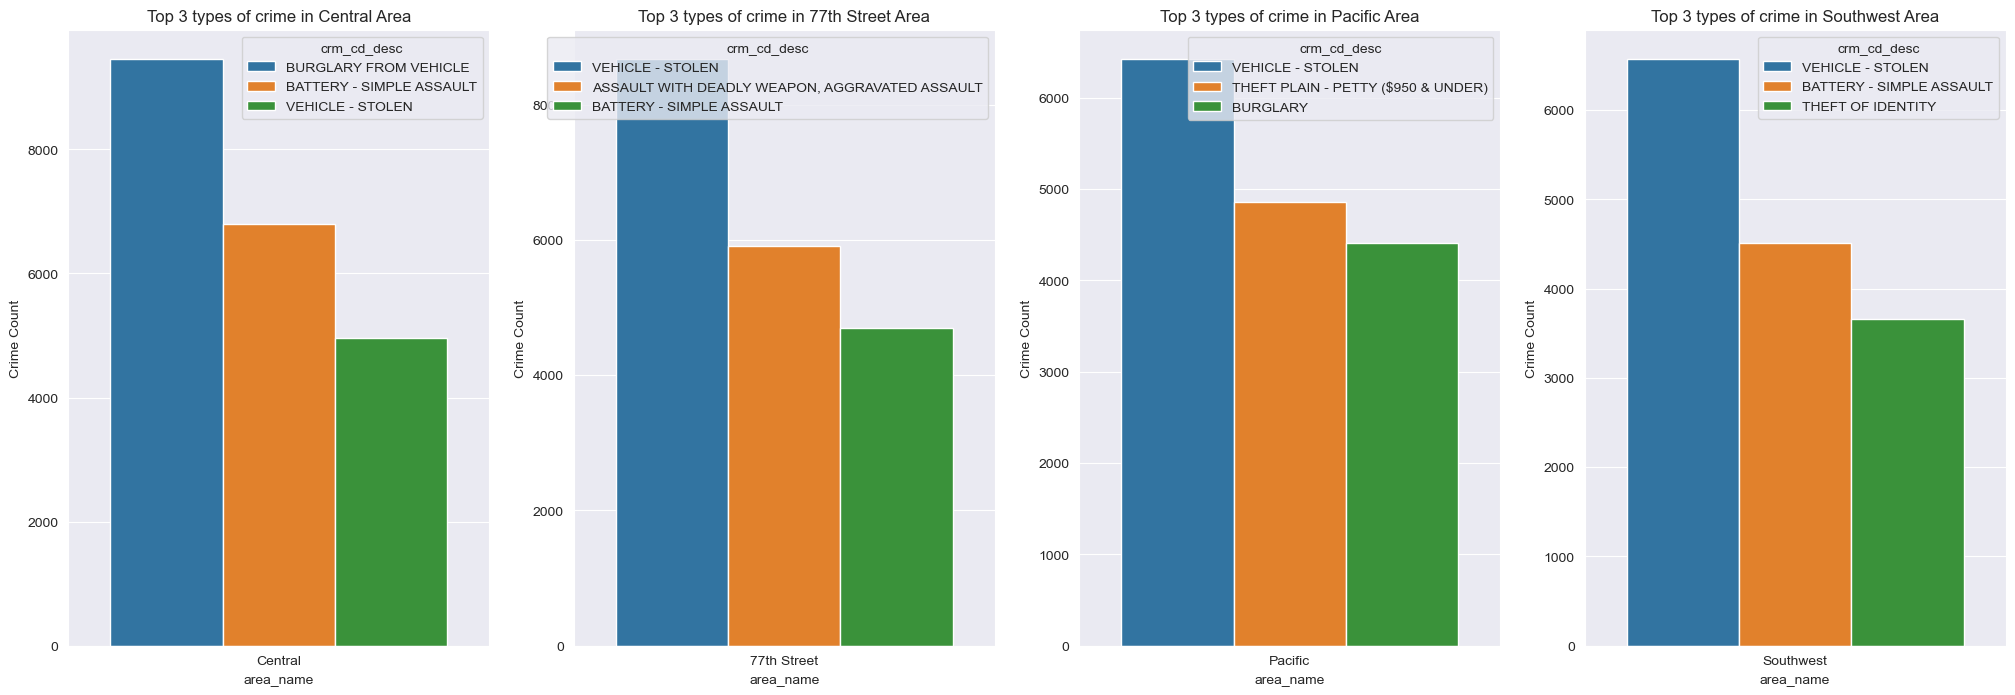

In [27]:
# The following lines of code obtains the three most frequent types of crime in areas with the highest crime.
# Areas with the highest crime determined based on crime_per_area() function output.

# Obtains the dr_no, area_name, and crm_cd_desc columns from the crime dataset
# Obtains the number of crimes per type of crime per area
# Sorts the dataframe by area and number of crime incidents
results_df_area_name = results_df[['dr_no', 'area_name', 'crm_cd_desc']]
results_df_area_name_crime_count = results_df_area_name.groupby(['area_name', 'crm_cd_desc'])['dr_no'].count()
area_name_crime_count_df = pd.DataFrame(results_df_area_name_crime_count)
area_name_crime_count_df = area_name_crime_count_df.reset_index()
area_name_crime_count_df = area_name_crime_count_df.sort_values(
    by=['area_name', 'dr_no'], ascending=[True, False]
)

# Obtains the top 3 types of crime in each area
top_3_crime_types_per_area = area_name_crime_count_df.groupby("area_name").head(3)

# Separates the top 3 types of crime for Central area into one dataframe
top_3_crime_types_per_area_central = top_3_crime_types_per_area[top_3_crime_types_per_area['area_name'] == "Central"]
top_3_crime_types_per_area_central = top_3_crime_types_per_area_central.rename(
    columns={'dr_no': "Crime Count"}
)

# Separates the top 3 types of crime for 77th Street area into one dataframe
top_3_crime_types_per_area_77th_street = top_3_crime_types_per_area[
    top_3_crime_types_per_area['area_name'] == "77th Street"
]
top_3_crime_types_per_area_77th_street = top_3_crime_types_per_area_77th_street.rename(
    columns={'dr_no': "Crime Count"}
)

# Separates the top 3 types of crime for Pacific area into one dataframe
top_3_crime_types_per_area_pacific = top_3_crime_types_per_area[
    top_3_crime_types_per_area['area_name'] == "Pacific"
]
top_3_crime_types_per_area_pacific = top_3_crime_types_per_area_pacific.rename(
    columns={'dr_no': "Crime Count"}
)

# Separates the top 3 types of crime for Southwest area into one dataframe
top_3_crime_types_per_area_southwest = top_3_crime_types_per_area[
    top_3_crime_types_per_area['area_name'] == "Southwest"
]
top_3_crime_types_per_area_southwest = top_3_crime_types_per_area_southwest.rename(
    columns={'dr_no': "Crime Count"}
)


def types_of_crime_per_area() -> None:
    """
    Creates four bar graphs, one for each of the top 4 areas with the highest overall crime. Each bar graph shows
    the three most frequent types of crime that occur in that area.
    :return: None
    """
    fig, axes = plt.subplots(1, 4, figsize=(25, 8))
    sns.barplot(x="area_name", y="Crime Count", data=top_3_crime_types_per_area_central, hue='crm_cd_desc', ax=axes[0])
    sns.barplot(
        x="area_name", y="Crime Count", data=top_3_crime_types_per_area_77th_street, hue='crm_cd_desc', ax=axes[1]
    )
    sns.barplot(x="area_name", y="Crime Count", data=top_3_crime_types_per_area_pacific, hue='crm_cd_desc', ax=axes[2])
    sns.barplot(
        x="area_name", y="Crime Count", data=top_3_crime_types_per_area_southwest, hue='crm_cd_desc', ax=axes[3]
    )
    axes[0].set_title("Top 3 types of crime in Central Area")
    axes[1].set_title("Top 3 types of crime in 77th Street Area")
    axes[2].set_title("Top 3 types of crime in Pacific Area")
    axes[3].set_title("Top 3 types of crime in Southwest Area")
    plt.show()


types_of_crime_per_area()

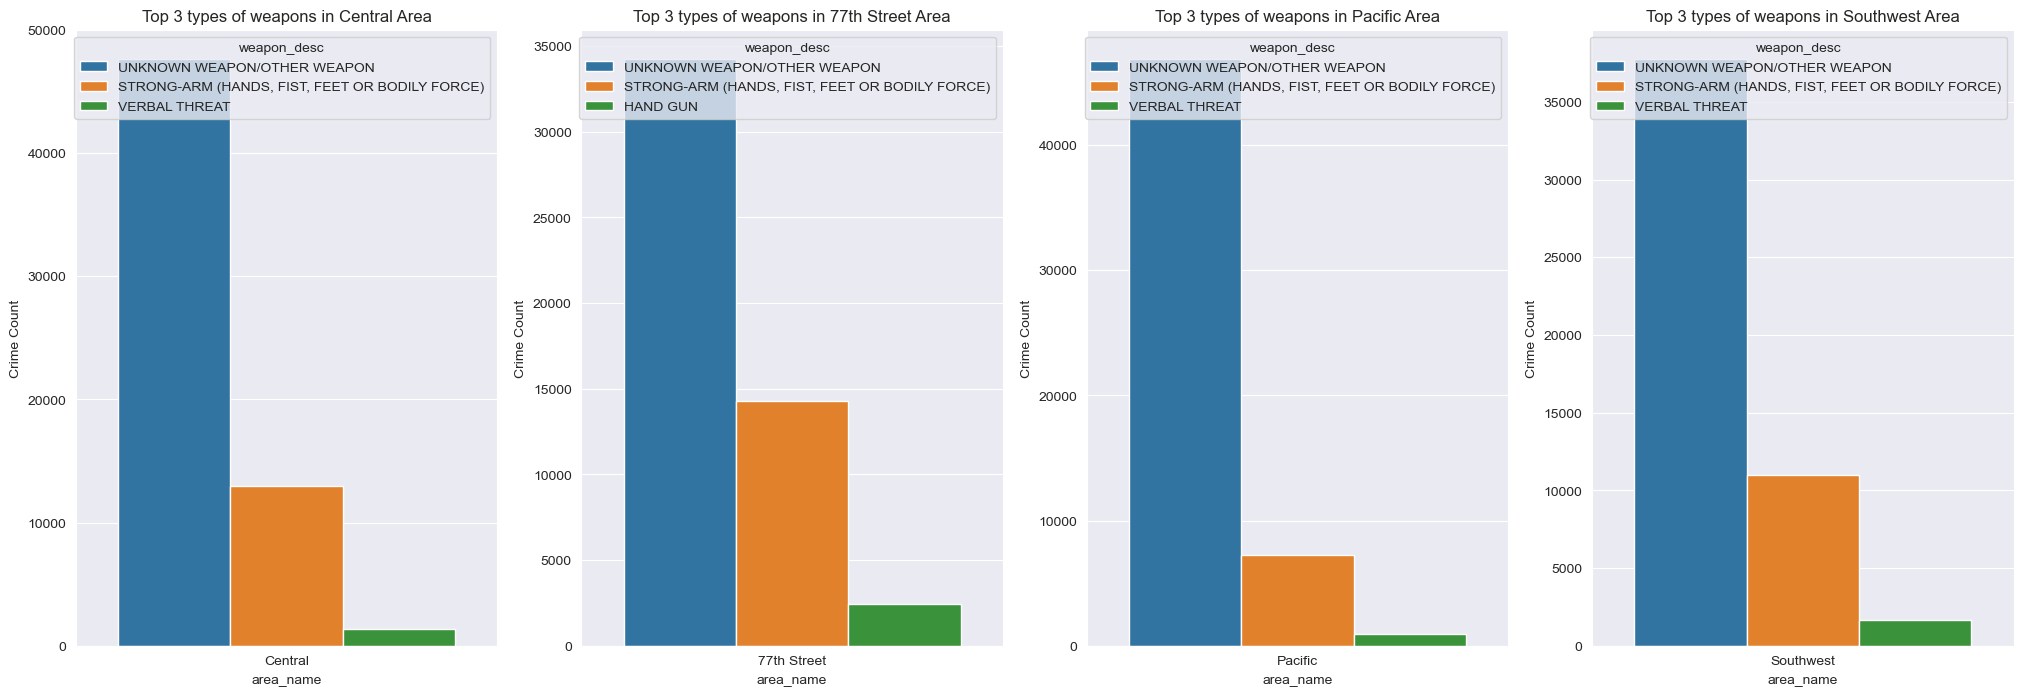

In [28]:
# The following lines of code obtains the three most frequent types of weapons in areas with the highest crime.
# Areas with the highest crime determined based on crime_per_area() function output.

# Obtains the dr_no, area_name, and weapon_desc columns from the crime dataset
# Obtains the number of crimes per weapon type per area
# Sorts the dataframe by area and number of crime incidents
results_df_weapon_desc = results_df[['dr_no', 'area_name', 'weapon_desc']]
results_df_weapon_desc_crime_count = results_df_weapon_desc.groupby(['area_name', 'weapon_desc'])['dr_no'].count()
weapon_desc_crime_count_df = pd.DataFrame(results_df_weapon_desc_crime_count)
weapon_desc_crime_count_df = weapon_desc_crime_count_df.reset_index()
weapon_desc_crime_count_df = weapon_desc_crime_count_df.sort_values(
    by=['area_name', 'dr_no'], ascending=[True, False]
)

# Obtains the top 3 types of weapons in each area
top_3_weapon_types_per_area = weapon_desc_crime_count_df.groupby("area_name").head(3)

# Separates the top 3 types of weapons in the Central Area into one dataframe
top_3_weapon_types_per_area_central = top_3_weapon_types_per_area[
    top_3_weapon_types_per_area['area_name'] == "Central"
]
top_3_weapon_types_per_area_central = top_3_weapon_types_per_area_central.rename(
    columns={'dr_no': "Crime Count"}
)

# Separates the top 3 types of weapons in the 77th Street Area into one dataframe
top_3_weapon_types_per_area_77th_street = top_3_weapon_types_per_area[
    top_3_weapon_types_per_area['area_name'] == "77th Street"
]
top_3_weapon_types_per_area_77th_street = top_3_weapon_types_per_area_77th_street.rename(
    columns={'dr_no': "Crime Count"}
)

# Separates the top 3 types of weapons in the Pacific Area into one dataframe
top_3_weapon_types_per_area_pacific = top_3_weapon_types_per_area[
    top_3_weapon_types_per_area['area_name'] == "Pacific"
]
top_3_weapon_types_per_area_pacific = top_3_weapon_types_per_area_pacific.rename(
    columns={'dr_no': "Crime Count"}
)

# Separates the top 3 types of weapons in the Southwest Area into one dataframe
top_3_weapon_types_per_area_southwest = top_3_weapon_types_per_area[
    top_3_weapon_types_per_area['area_name'] == "Southwest"
]
top_3_weapon_types_per_area_southwest = top_3_weapon_types_per_area_southwest.rename(
    columns={'dr_no': "Crime Count"}
)


def types_of_weapons_per_area() -> None:
    """
    Creates four bar graphs, one for each of the top 4 areas with the highest overall crime. Each bar graph shows
    the three most frequent types of weapons that are used in crime incidents in that area.
    :return: None
    """
    fig, axes = plt.subplots(1, 4, figsize=(25, 8))
    sns.barplot(x="area_name", y="Crime Count", data=top_3_weapon_types_per_area_central, hue='weapon_desc', ax=axes[0])
    sns.barplot(x="area_name", y="Crime Count", data=top_3_weapon_types_per_area_77th_street, hue='weapon_desc',
                ax=axes[1])
    sns.barplot(x="area_name", y="Crime Count", data=top_3_weapon_types_per_area_pacific, hue='weapon_desc', ax=axes[2])
    sns.barplot(
        x="area_name", y="Crime Count", data=top_3_weapon_types_per_area_southwest, hue='weapon_desc', ax=axes[3]
    )
    axes[0].set_title("Top 3 types of weapons in Central Area")
    axes[1].set_title("Top 3 types of weapons in 77th Street Area")
    axes[2].set_title("Top 3 types of weapons in Pacific Area")
    axes[3].set_title("Top 3 types of weapons in Southwest Area")
    plt.show()


types_of_weapons_per_area()

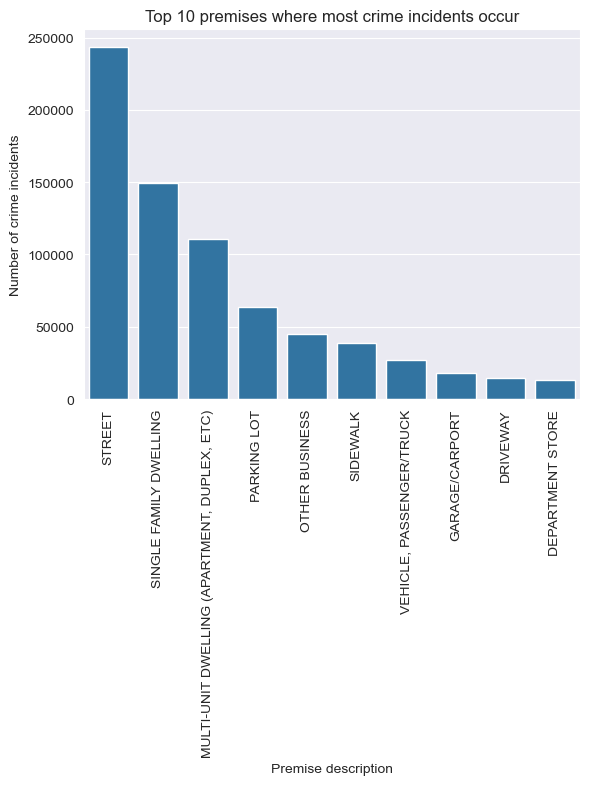

In [29]:
def premise_count_of_crime() -> None:
    """
    Creates a barplot with the top 10 premises that have the most amount of crime.
    :return: None
    """
    count_of_incidents_per_premise_df_top10, premise_table_top10 = premise_statistics()
    sns.barplot(data=count_of_incidents_per_premise_df_top10, x='premis_desc', y='Number of crime incidents')
    plt.ylabel("Number of crime incidents")
    plt.xlabel("Premise description")
    plt.title("Top 10 premises where most crime incidents occur")
    plt.xticks(rotation=90)
    plt.show()


premise_count_of_crime()


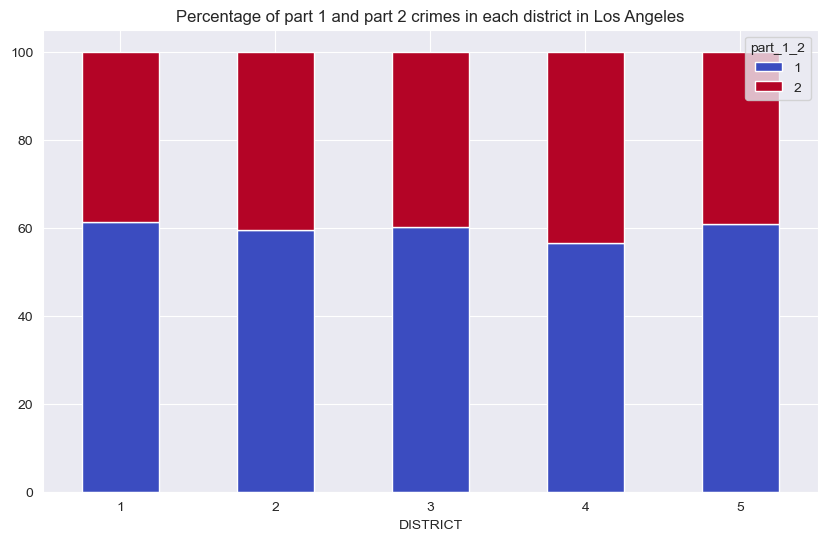

In [30]:
def part1_part2_crimes() -> None:
    """
    Creates a stacked barplot that shows the percentage of part 1 and part 2 crimes in each district.
    :return: None
    """
    part1_part2_df, part1_part2_table = part1_part2_crimes_analysis()
    part1_part2_df = part1_part2_df.pivot(index="DISTRICT", columns="part_1_2", values="Percentage of part 1 and part"
                                                                                       " 2 crimes in this district")
    part1_part2_df.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='coolwarm')
    plt.title("Percentage of part 1 and part 2 crimes in each district in Los Angeles")
    plt.xticks(rotation=0)
    plt.show()


part1_part2_crimes()


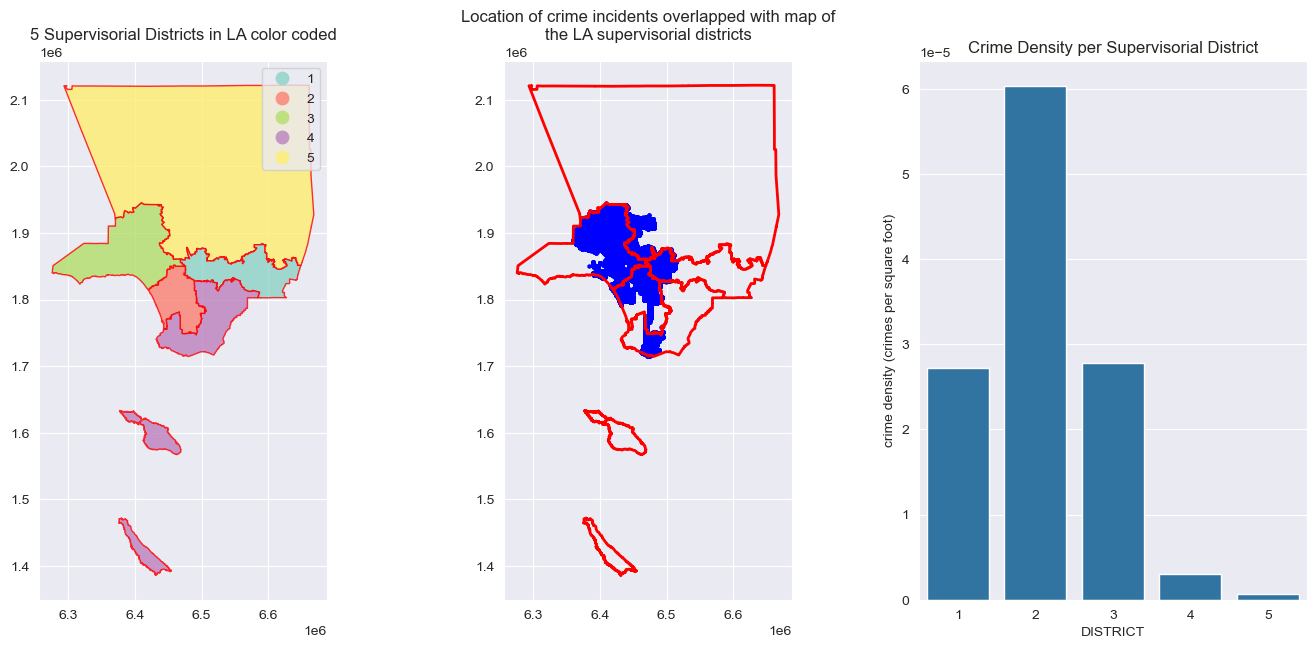

In [31]:
def crime_in_districts_map() -> None:
    """
    Plots the locations of all the crime incidents on a map of the districts in Los Angeles.
    Also plots a bar plot of crime density per supervisorial district in Los Angeles.
    :return: None
    """
    fig, axes = plt.subplots(1, 3, figsize=(17, 7))
    gdf_districts.boundary.plot(color="red", linewidth=2, ax=axes[1])
    gdf_joined_crime_districts.plot(marker='o', color='blue', markersize=5, ax=axes[1])
    gdf_districts.plot(edgecolor='red', column="DISTRICT", alpha=0.8, legend=True, ax=axes[0], cmap='Set3')
    poverty_and_crime_graph, table = poverty_and_district_crime()
    sns.barplot(
        x=poverty_and_crime_graph["DISTRICT"], y=poverty_and_crime_graph["crime density (crimes per square foot)"],
        ax=axes[2]
    )
    wrapped_title = textwrap.fill(
        "Location of crime incidents overlapped with map of the LA supervisorial districts", width=50
    )
    axes[0].set_title("5 Supervisorial Districts in LA color coded", fontsize=12)
    axes[1].set_title(wrapped_title, fontsize=12)
    axes[2].set_title("Crime Density per Supervisorial District")
    plt.show()


crime_in_districts_map()


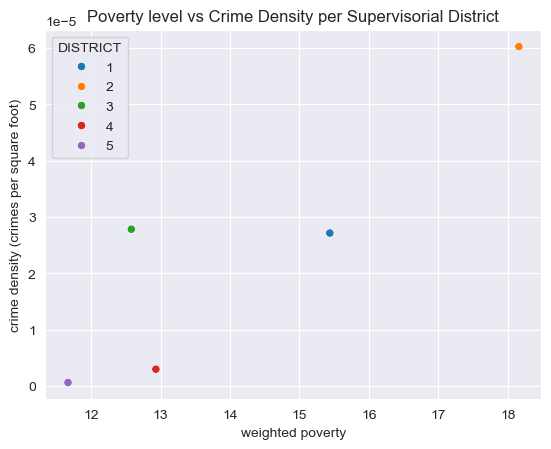

In [32]:
def poverty_and_crime_district_scatterplot() -> None:
    """
    Creates a scatterplot, plotting the weighted poverty level and crime density for each district in Los Angeles.
    :return: None
    """
    poverty_and_crime_graph, table = poverty_and_district_crime()
    sns.scatterplot(
        data=poverty_and_crime_graph, x="weighted poverty", y="crime density (crimes per square foot)", hue="DISTRICT"
    )
    plt.title("Poverty level vs Crime Density per Supervisorial District")
    plt.show()


poverty_and_crime_district_scatterplot()


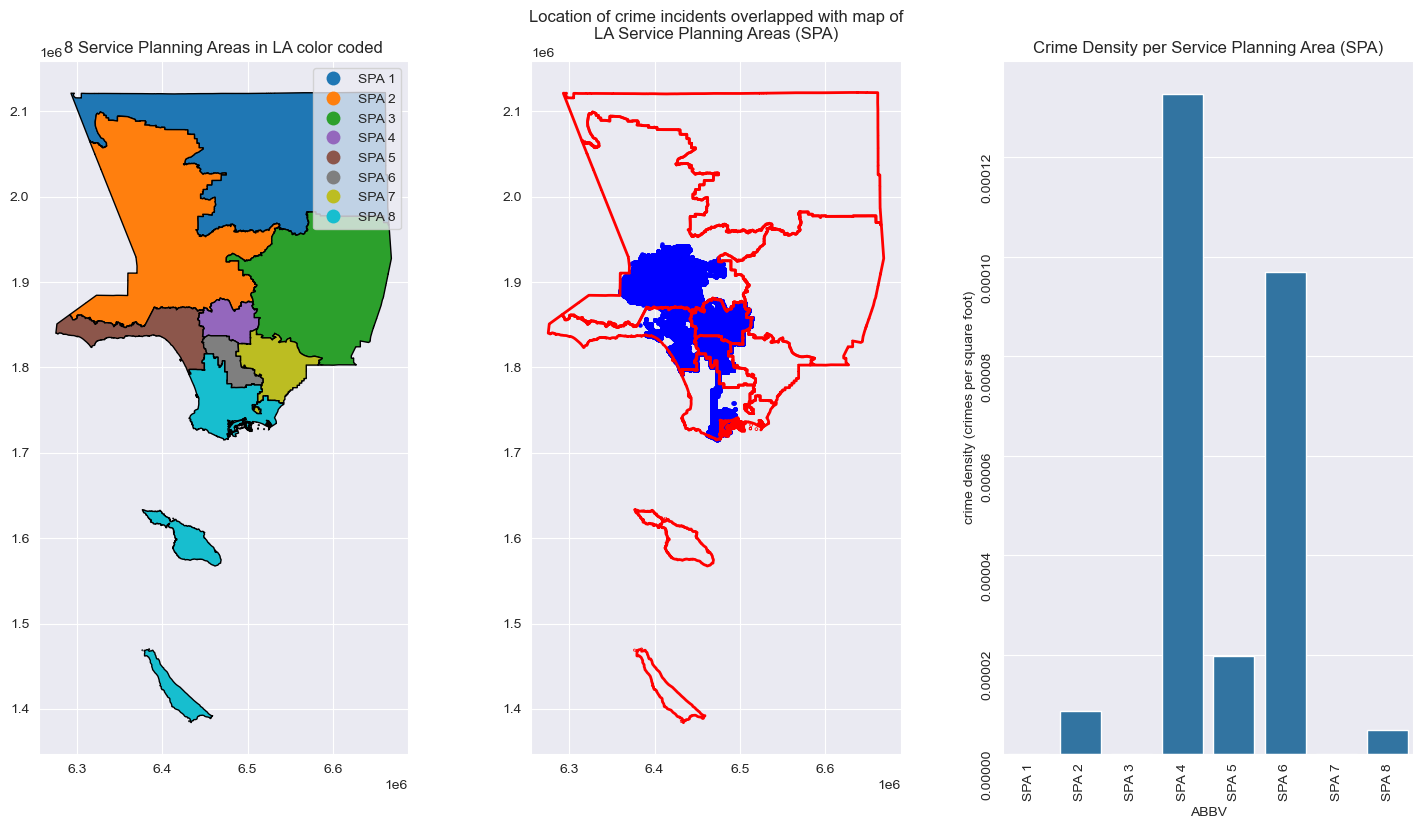

In [33]:
def crime_in_spa_map() -> None:
    """
    Plots the locations of all the crime incidents on a map of the SPA's (Service Planning Areas) in Los Angeles.
    :return: None
    """
    fig, axes = plt.subplots(1, 3, figsize=(18, 9))
    gdf_spa.boundary.plot(color="red", linewidth=2, ax=axes[1])
    gdf_joined_crime_spa.plot(marker='o', color='blue', markersize=5, ax=axes[1])
    gdf_spa.plot(edgecolor='black', column="ABBV", legend=True, ax=axes[0])
    poverty_and_crime_spa_graph, table = poverty_and_spa_crime()
    sns.barplot(data=poverty_and_crime_spa_graph, x="ABBV", y="crime density (crimes per square foot)", ax=axes[2])

    wrapped_title = textwrap.fill(
        "Location of crime incidents overlapped with map of LA Service Planning Areas (SPA)", width=50
    )
    axes[0].set_title("8 Service Planning Areas in LA color coded", fontsize=12)
    axes[1].set_title(wrapped_title, fontsize=12)
    axes[2].set_title("Crime Density per Service Planning Area (SPA)")
    axes[2].tick_params(rotation=90)
    plt.show()


crime_in_spa_map()


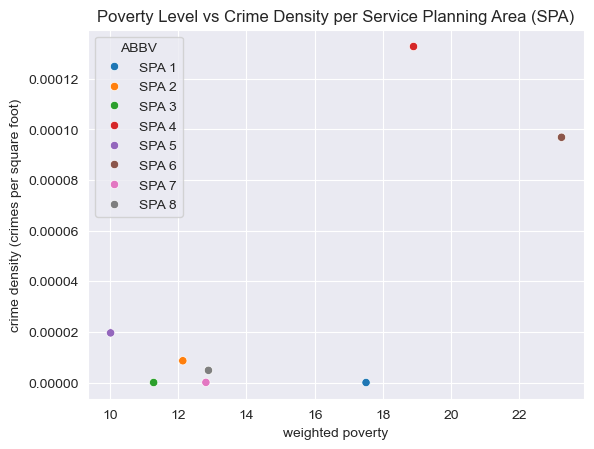

In [34]:
def poverty_and_crime_spa_scatterplot() -> None:
    """
    Creates a scatterplot, plotting the weighted poverty level and crime density for each SPA in Los Angeles.
    :return: None
    """
    poverty_and_crime_spa_graph, table = poverty_and_spa_crime()
    sns.scatterplot(
        data=poverty_and_crime_spa_graph, x="weighted poverty", y="crime density (crimes per square foot)", hue="ABBV"
    )
    plt.title("Poverty Level vs Crime Density per Service Planning Area (SPA)")
    plt.show()


poverty_and_crime_spa_scatterplot()


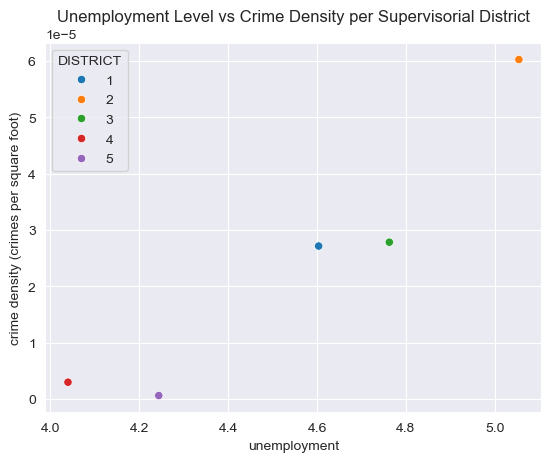

In [35]:
def unemployment_and_crime_district_scatterplot() -> None:
    """
    Creates a scatterplot, plotting the average unemployment level and crime density for each district in Los Angeles.
    :return: None
    """
    unemployment_and_crime_graph, table = unemployment_analysis()
    sns.scatterplot(
        data=unemployment_and_crime_graph, x="unemployment", y="crime density (crimes per square foot)", hue="DISTRICT"
    )
    plt.title("Unemployment Level vs Crime Density per Supervisorial District")
    plt.show()


unemployment_and_crime_district_scatterplot()

The pearson correlation coefficient is 0.5804309777090152


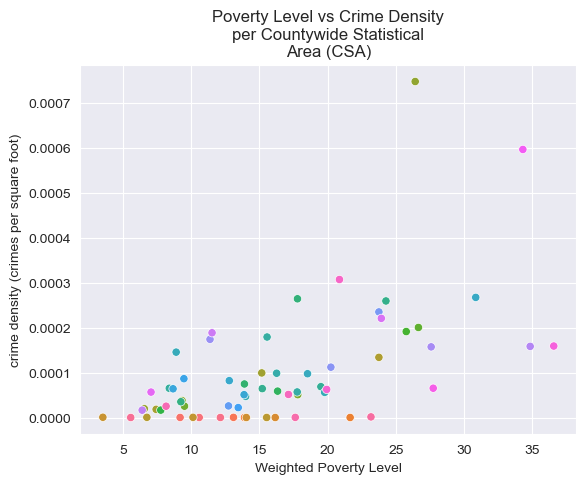

In [36]:
def poverty_and_crime_csa_scatterplot() -> None:
    """
    Creates a scatterplot, plotting the weighted poverty level and crime density for multiple csa's in Los Angeles.
    :return: None
    """
    csa_poverty_and_crime_density_data, table = csa_crime_poverty_data()
    sns.scatterplot(
        data=csa_poverty_and_crime_density_data, x="Weighted Poverty Level",
        y="crime density (crimes per square foot)", hue="LABEL",
        legend=False
    )
    plt.title(textwrap.fill("Poverty Level vs Crime Density per Countywide Statistical Area (CSA)", width=30))
    print(f"The pearson correlation coefficient is {csa_poverty_and_crime_density_data["Weighted Poverty Level"]
          .corr(csa_poverty_and_crime_density_data["crime density (crimes per square foot)"])}")
    plt.show()


poverty_and_crime_csa_scatterplot()

The pearson correlation coefficient is 0.16955758380668906


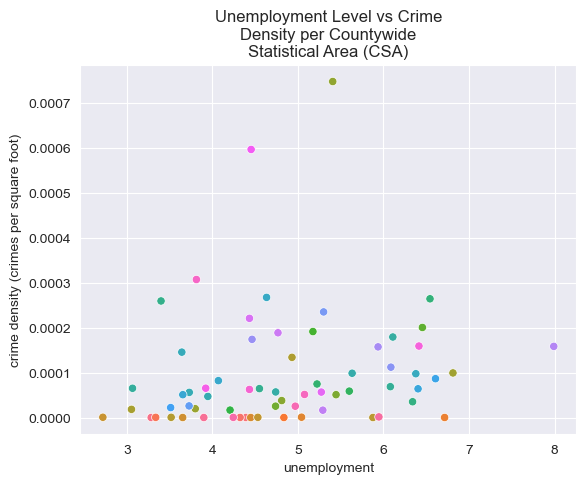

In [37]:
def unemployment_and_crime_csa_scatterplot() -> None:
    """
    Creates a scatterplot, plotting the average unemployment level and crime density for multiple csa's in Los Angeles.
    :return: None
    """
    csa_unemployment_and_crime_density_data, table = csa_crime_unemployment_data()
    sns.scatterplot(
        data=csa_unemployment_and_crime_density_data,
        x="unemployment", y="crime density (crimes per square foot)",
        hue="LABEL",
        legend=False
    )
    plt.title(
        textwrap.fill("Unemployment Level vs Crime Density per Countywide Statistical Area (CSA)", width=30)
    )
    print(f"The pearson correlation coefficient is {csa_unemployment_and_crime_density_data["unemployment"].corr(
        csa_unemployment_and_crime_density_data["crime density (crimes per square foot)"])}"
    )
    plt.show()


unemployment_and_crime_csa_scatterplot()